# 03 · Binary distillation: the McCabe-Thiele method

A distillation column is a stack of flashes with the vapour of each feeding the stage above and the liquid the
stage below, and reflux at the top to keep the vapour climbing towards purity. McCabe and Thiele (1925)
showed that with constant molar overflow the whole column is a staircase on the x-y diagram. This notebook
draws it: operating lines, the q-line, stage stepping, feed location, minimum reflux, minimum stages and the
reflux-versus-stages trade-off.

**What you will learn**
- derive and draw the operating lines and the q-line
- step off stages and locate the feed stage
- find the minimum reflux and minimum stages
- account for Murphree efficiency and handle any equilibrium curve

**Before you start:** notebooks 01 and 02  ·  **Time:** about 75 min

In [1]:
try:                      # on Google Colab (or anywhere engsep is missing): install it from GitHub
    import engsep
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engsep"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engsep import distillation as dist
from engsep import vle
from engsep.vle import y_from_alpha
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Operating lines and the staircase

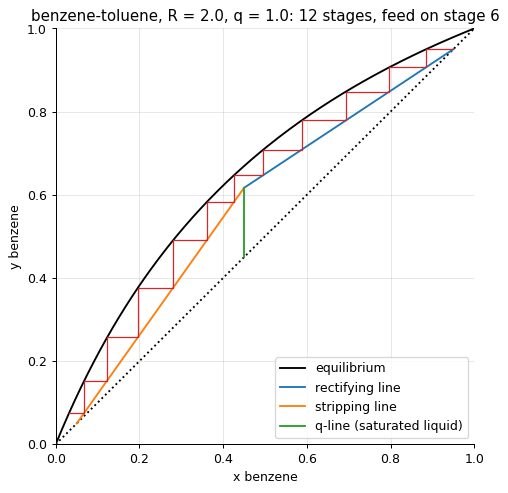

12 theoretical stages including the reboiler; feed on stage 6 from the top


In [2]:
alpha = vle.geometric_mean_alpha(("benzene", "toluene"), ideal=True)
y_eq = lambda x: y_from_alpha(x, alpha)
xD, xB, zF, R, q = 0.95, 0.05, 0.45, 2.0, 1.0
mt = dist.mccabe_thiele(y_eq, xD, xB, zF, R, q)
def draw(mt, title):
    xs = np.linspace(0, 1, 200)
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.plot(xs, y_eq(xs), "k", label="equilibrium"); ax.plot([0, 1], [0, 1], "k:")
    ol = mt["lines"]
    ax.plot([ol["x_int"], xD], [ol["y_int"], xD], "C0", label="rectifying line"); ax.plot([xB, ol["x_int"]], [xB, ol["y_int"]], "C1", label="stripping line")
    if ol["q_line"] is not None:
        ax.plot([zF, ol["x_int"]], [zF, ol["y_int"]], "C2", label="q-line")
    else:
        ax.plot([zF, zF], [zF, ol["y_int"]], "C2", label="q-line (saturated liquid)")
    ax.step(mt["x"], mt["y"], "C3", where="post", lw=1)
    ax.set(xlabel="x benzene", ylabel="y benzene", xlim=(0, 1), ylim=(0, 1), title=title); ax.legend(loc="lower right"); plt.show()
draw(mt, f"benzene-toluene, R = {R}, q = {q}: {mt['stages']} stages, feed on stage {mt['feed_stage']}")
print(f"{mt['stages']} theoretical stages including the reboiler; feed on stage {mt['feed_stage']} from the top")

The rectifying line comes from a balance around the top of the column, slope $R/(R+1)$ through $(x_D, x_D)$;
the stripping line from a balance around the bottom, through $(x_B, x_B)$; they meet on the q-line, which
encodes the feed's thermal condition. Stepping between the operating lines and the equilibrium curve counts
the stages, and the step that crosses the intersection is the feed stage.

## The feed condition: the q-line

In [3]:
R_cmp = 3.0                                                          # above the minimum for every feed condition below
for q_, label in ((1.3, "subcooled liquid"), (1.0, "saturated liquid"), (0.5, "half vaporised"), (0.0, "saturated vapour")):
    mt_ = dist.mccabe_thiele(y_eq, xD, xB, zF, R_cmp, q_)
    print(f"q = {q_:4.1f} ({label:<17}): at R = {R_cmp}: {mt_['stages']:2d} stages, feed stage {mt_['feed_stage']}; minimum reflux {dist.minimum_reflux(y_eq, xD, zF, q_)['R_min']:.3f}")

q =  1.3 (subcooled liquid ): at R = 3.0: 10 stages, feed stage 5; minimum reflux 1.087
q =  1.0 (saturated liquid ): at R = 3.0: 10 stages, feed stage 5; minimum reflux 1.282
q =  0.5 (half vaporised   ): at R = 3.0: 11 stages, feed stage 6; minimum reflux 1.772
q =  0.0 (saturated vapour ): at R = 3.0: 13 stages, feed stage 7; minimum reflux 2.484


The q-line has slope $q/(q-1)$: vertical for a saturated liquid, horizontal for a saturated vapour. A
vapour feed needs almost twice the minimum reflux of a liquid feed (the rectifying section must carry the
extra vapour) and, at the same reflux, more stages; a subcooled feed condenses vapour in the stripping
section and helps - at R = 2 the vapour feed cannot even be separated, which is why the comparison is run
at R = 3. Feed preheating is a lever on the
whole column, decided by this geometry and the utility costs.

## Minimum reflux and minimum stages

minimum reflux R_min = 1.282 (pinch at x = 0.45); Fenske: N_min = 6.51 -> 7 stages at total reflux


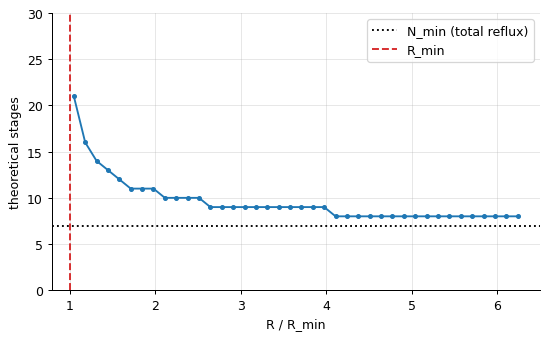

In [4]:
rm = dist.minimum_reflux(y_eq, xD, zF, q)
N_min = dist.minimum_stages(y_eq, xD, xB)
print(f"minimum reflux R_min = {rm['R_min']:.3f} (pinch at x = {rm['x_pinch']:.2f}); Fenske: N_min = {dist.fenske(xD, xB, alpha):.2f} -> {N_min} stages at total reflux")
Rs = np.linspace(1.05 * rm["R_min"], 8, 40)
Ns = [dist.mccabe_thiele(y_eq, xD, xB, zF, R_, q)["stages"] for R_ in Rs]
fig, ax = plt.subplots(); ax.plot(Rs / rm["R_min"], Ns, "o-", ms=3); ax.axhline(N_min, color="k", ls=":", label="N_min (total reflux)"); ax.axvline(1.0, color="C3", ls="--", label="R_min"); ax.set(xlabel="R / R_min", ylabel="theoretical stages", ylim=(0, 30)); ax.legend(); plt.show()

At minimum reflux the operating lines touch the equilibrium curve and the staircase needs infinitely many
steps at the pinch; at total reflux the operating lines coincide with the diagonal and the stages are fewest.
Real columns run at 1.2-1.5 times $R_{min}$: the steep part of the curve is where stages are expensive and
the flat part where reflux (reboiler steam) is. The optimum is an economic balance, computed in notebook 04.

## Plate efficiency

In [5]:
for E in (1.0, 0.8, 0.6):
    mt_ = dist.mccabe_thiele(y_eq, xD, xB, zF, R, q, murphree=E)
    print(f"Murphree vapour efficiency {E:.0%}: {mt_['stages']} stages (real trays {mt_['stages'] - 1} + reboiler)")
print(f"O'Connell overall efficiency for alpha = {alpha:.2f} and mu = 0.3 mPa s: {dist.oconnell_efficiency(alpha, 0.3):.2f}")

Murphree vapour efficiency 100%: 12 stages (real trays 11 + reboiler)
Murphree vapour efficiency 80%: 15 stages (real trays 14 + reboiler)
Murphree vapour efficiency 60%: 20 stages (real trays 19 + reboiler)
O'Connell overall efficiency for alpha = 2.47 and mu = 0.3 mPa s: 0.53


Real trays do not reach equilibrium: with a Murphree efficiency of 60 % the staircase takes shorter steps
and the column needs half again as many trays. O'Connell's correlation predicts overall efficiencies from
viscosity and relative volatility - about 0.5-0.6 for benzene-toluene at its 0.3 mPa s - and the plant column
of notebook 17 will be judged against it.

## A hard separation: ethanol-water

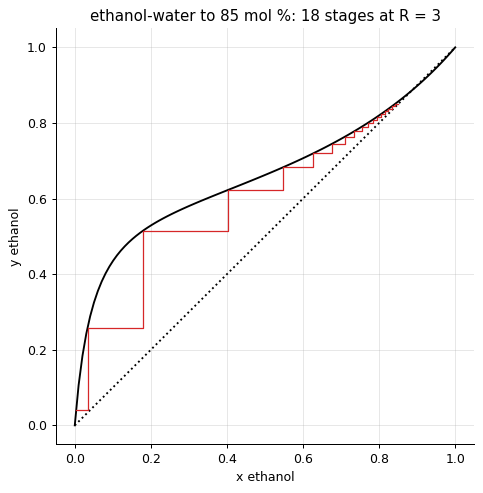

minimum reflux 1.68; tangent pinch: True; stages at R = 3: 18


In [6]:
y_ew = lambda x: vle.equilibrium_y(("ethanol", "water"), x)
mt_ew = dist.mccabe_thiele(y_ew, 0.85, 0.02, 0.30, R=3.0)
xs = np.linspace(0, 1, 100)
fig, ax = plt.subplots(figsize=(6, 6)); ax.plot(xs, [y_ew(x) for x in xs], "k"); ax.plot([0, 1], [0, 1], "k:"); ax.step(mt_ew["x"], mt_ew["y"], "C3", where="post", lw=1); ax.set(xlabel="x ethanol", ylabel="y ethanol", title=f"ethanol-water to 85 mol %: {mt_ew['stages']} stages at R = 3"); plt.show()
rm_ew = dist.minimum_reflux(y_ew, 0.85, 0.30)
print(f"minimum reflux {rm_ew['R_min']:.2f}; tangent pinch: {rm_ew['tangent_pinch']}; stages at R = 3: {mt_ew['stages']}")

Near the azeotrope the equilibrium curve hugs the diagonal and each stage gains almost nothing: the last
few percent of purity cost as many stages as the first eighty. The library's equilibrium curve here is the
Wilson model, checked against the data in notebook 01 - McCabe-Thiele works with any curve, which is its
enduring advantage over shortcut formulas that assume constant α.

## Inside the algorithm: one stage of the staircase

In [7]:
from scipy import optimize
x_, y_ = xD, xD
x_ = optimize.brentq(lambda xx: y_eq(xx) - y_, 0, 1)         # horizontal step to the equilibrium curve
y_ = R / (R + 1) * x_ + xD / (R + 1)                          # vertical step to the operating line
print("by hand: after stage 1, x =", round(x_, 4), "y =", round(y_, 4), "; library:", np.round(mt["x"][1], 4), np.round(mt["y"][2], 4))

by hand: after stage 1, x = 0.8849 y = 0.9066 ; library: 0.8849 0.9066


## Exercises
1. Design the benzene-toluene column for a 40 % vapour feed (q = 0.6) and for a feed preheated to its bubble point; compare stages, feed location and R_min. Estimate which is cheaper if a preheater costs 20 % of a reboiler.
2. For the ethanol-water column, plot the number of stages against the distillate purity from 0.70 to 0.88 at R = 3 and R = 6. Explain the shape from the equilibrium curve, and what happens at 0.89.
3. **Implement it yourself:** write your own McCabe-Thiele stepping function for a saturated-liquid feed and reproduce the stage count and feed stage of the benzene-toluene example.